In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
data = pd.read_csv("../data.csv", sep=";")

print("Dataset loaded successfully!")
print(data.head())
print(data.shape)

Dataset loaded successfully!
   Marital status  Application mode  Application order  Course  \
0               1                17                  5     171   
1               1                15                  1    9254   
2               1                 1                  5    9070   
3               1                17                  2    9773   
4               2                39                  1    8014   

   Daytime/evening attendance\t  Previous qualification  \
0                             1                       1   
1                             1                       1   
2                             1                       1   
3                             1                       1   
4                             0                       1   

   Previous qualification (grade)  Nacionality  Mother's qualification  \
0                           122.0            1                      19   
1                           160.0            1                       1 

In [3]:
# Separate features and target
X = data.drop("Target", axis=1)
y = data["Target"]

# Convert categorical columns into numbers
X = pd.get_dummies(X, drop_first=True)

# Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Data preprocessing completed!")
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Data preprocessing completed!
Training data: (3539, 36)
Testing data: (885, 36)


In [4]:
# 1. Logistic Regression
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)


# 2. Decision Tree
decision_model = DecisionTreeClassifier(random_state=42)
decision_model.fit(X_train, y_train)


# 3. Random Forest
random_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

random_model.fit(X_train, y_train)

print("All three models trained successfully!")

All three models trained successfully!


In [5]:
# Make predictions using all three models

y_pred_logistic = logistic_model.predict(X_test)

y_pred_decision = decision_model.predict(X_test)

y_pred_random = random_model.predict(X_test)

print("Predictions completed successfully!")

Predictions completed successfully!


In [6]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred_logistic),
        accuracy_score(y_test, y_pred_decision),
        accuracy_score(y_test, y_pred_random)
    ],

    "Precision": [
        precision_score(y_test, y_pred_logistic, average="weighted"),
        precision_score(y_test, y_pred_decision, average="weighted"),
        precision_score(y_test, y_pred_random, average="weighted")
    ],

    "Recall": [
        recall_score(y_test, y_pred_logistic, average="weighted"),
        recall_score(y_test, y_pred_decision, average="weighted"),
        recall_score(y_test, y_pred_random, average="weighted")
    ],

    "F1 Score": [
        f1_score(y_test, y_pred_logistic, average="weighted"),
        f1_score(y_test, y_pred_decision, average="weighted"),
        f1_score(y_test, y_pred_random, average="weighted")
    ]
})

print(results.round(3))

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression     0.768      0.750   0.768     0.753
1        Decision Tree     0.697      0.702   0.697     0.699
2        Random Forest     0.767      0.754   0.767     0.754


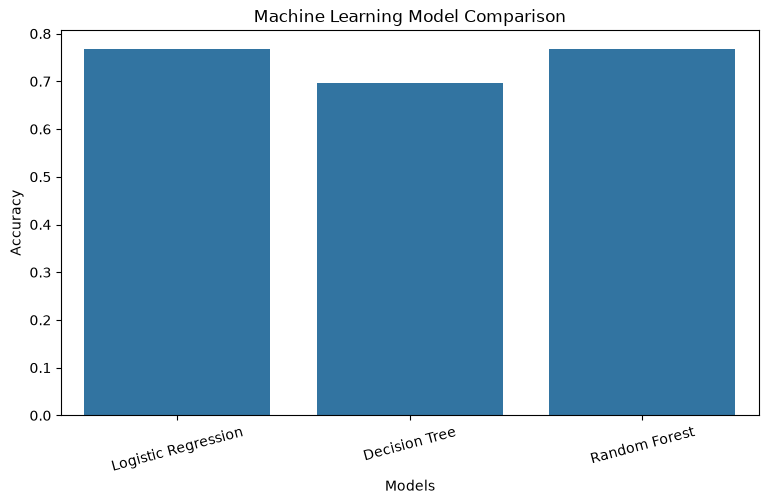

In [7]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x="Model",
    y="Accuracy",
    data=results
)

plt.title("Machine Learning Model Comparison")
plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.xticks(rotation=15)
plt.show()

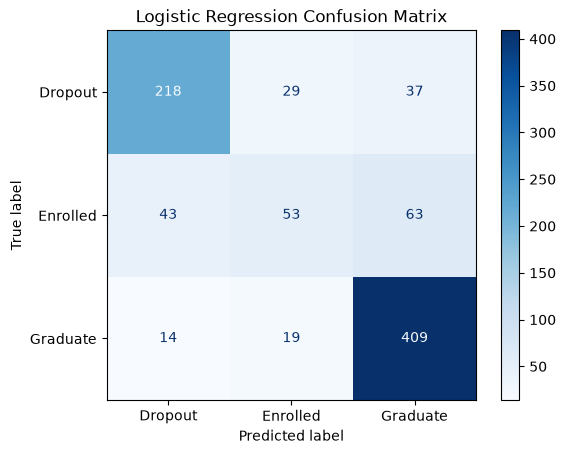

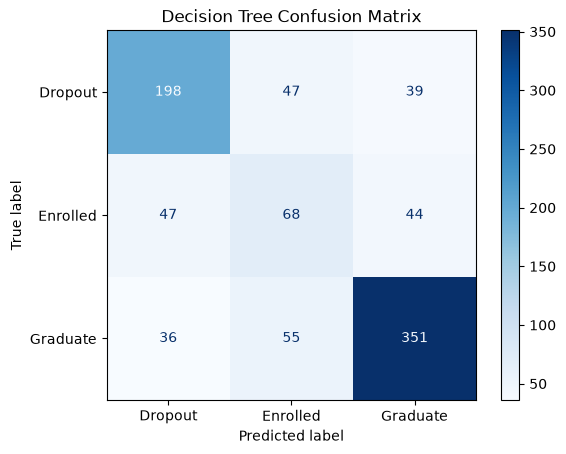

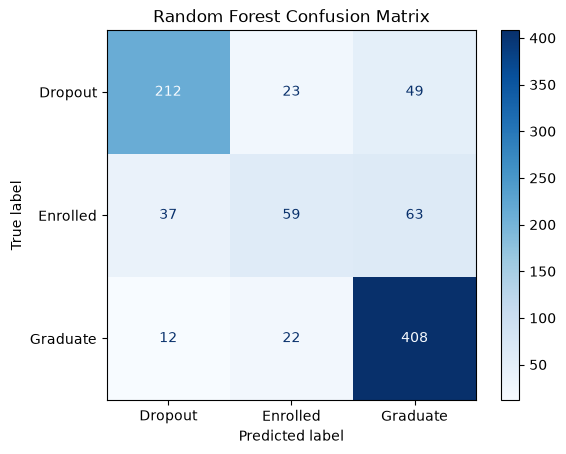

In [8]:
predictions = {
    "Logistic Regression": y_pred_logistic,
    "Decision Tree": y_pred_decision,
    "Random Forest": y_pred_random
}

for name, prediction in predictions.items():

    cm = confusion_matrix(y_test, prediction)

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=logistic_model.classes_
    )

    display.plot(cmap="Blues")
    plt.title(name + " Confusion Matrix")
    plt.show()

In [9]:
best_model = results.loc[results["F1 Score"].idxmax()]

print("Best Model:", best_model["Model"])
print("Best F1 Score:", best_model["F1 Score"])

Best Model: Random Forest
Best F1 Score: 0.7539029502277624


In [10]:
results.to_csv("model_comparison_results.csv", index=False)

print("Model comparison results saved successfully!")

Model comparison results saved successfully!
